<a href="https://colab.research.google.com/github/Saurabh-Kurhade-Patil/GenAI/blob/main/retrievers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install langchain chromadb faiss-cpu openai tiktoken langchain_openai langchain-community wikipedia

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 60.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 77.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 145.6/145.6 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 76.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 103.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 32.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 573.0/573.0 kB 34.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 10.5 MB/s eta 0:00:00
   ━━━━━━

In [2]:
%pip install -qU langchain-community langchain-huggingface langchain-text-splitters sentence-transformers faiss-cpu beautifulsoup4 langchain

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 740.6/740.6 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 109.9/109.9 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.4/165.4 kB 10.7 MB/s eta 0:00:00


In [18]:
%pip install -U langchain-community wikipedia requests

In [70]:
import os
os.environ['HF_TOKEN'] = 'hf_'

## Wikipedia Retriever

In [20]:
import requests

url = "https://en.wikipedia.org/w/api.php"

params = {
    "action": "query",
    "list": "search",
    "srsearch": "geopolitical history of India and Pakistan",
    "format": "json"
}

response = requests.get(
    url,
    params=params,
    headers={"User-Agent": "MyLangChainProject/1.0 (learning@example.com)"},
    timeout=20
)

print("Status:", response.status_code)
print("Response:", response.text[:300])

response.raise_for_status()
data = response.json()

for item in data["query"]["search"]:
    print(item["title"])

Status: 200
Response: {"batchcomplete":"","continue":{"sroffset":10,"continue":"-||"},"query":{"searchinfo":{"totalhits":1082},"search":[{"ns":0,"title":"India\u2013Pakistan war of 1971","pageid":464071,"size":227124,"wordcount":20750,"snippet":"The <span class=\"searchmatch\">India</span>\u2013<span class=\"searchmatch\
India–Pakistan war of 1971
2025 India–Pakistan conflict
India–Pakistan wars and conflicts
India–Pakistan war of 1965
History of Pakistan (1947–present)
Maritime history of Pakistan
United States aid to Pakistan
Indian subcontinent
Dominion of Pakistan
Asim Munir


In [24]:
import wikipedia
from langchain_community.retrievers import WikipediaRetriever

retriever = WikipediaRetriever(
    top_k_results=2,
    lang="en"
)

query = "The black hole concept in the Scientific way"

docs = retriever.invoke(query)

for doc in docs:
    print(doc.page_content[:1000])
    print("-" * 80)

A black hole is an astronomical body so compact that its gravity prevents anything, including light, from escaping. Albert Einstein's theory of general relativity, which describes gravitation as the curvature of spacetime, predicts that any sufficiently compact mass will form a black hole. The boundary of no escape is called the event horizon. In general relativity, crossing a black hole's event horizon traps an object inside but produces no locally detectable change. General relativity also predicts that every black hole should have a central singularity, where the curvature of spacetime is infinite.
Objects whose gravitational fields are too strong for light to escape were first considered in the 18th century. In 1916, the first solution of general relativity that would characterise a black hole was found. By the late 1950s, this solution began to be interpreted physically as a region of space from which nothing can escape. Black holes were long considered a mathematical curiosity; i

## Vector Store Retrievers

In [25]:
from langchain_community.vectorstores import Chroma
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_core.documents import Document

In [26]:
documents = [
    Document(page_content="LangChain helps developers build LLM applications easily."),
    Document(page_content="Chroma is a vector database optimized for LLM-based search."),
    Document(page_content="Embeddings convert text into high-dimensional vectors."),
    Document(page_content="OpenAI provides powerful embedding models."),
]

In [28]:
embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2",
    model_kwargs={"device": "cpu"},
    encode_kwargs={"normalize_embeddings": True}
)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [29]:
vector_store = Chroma.from_documents(
    documents = documents,
    embedding = embeddings,
    collection_name = "my_collection"
)

In [31]:
retriever = vector_store.as_retriever(search_kwargs={"k":2})

In [34]:
query = 'what is chroma used for'
result = retriever.invoke(query)

In [35]:
result

[Document(metadata={}, page_content='Chroma is a vector database optimized for LLM-based search.'),
 Document(metadata={}, page_content='LangChain helps developers build LLM applications easily.')]

In [37]:
vector_store.similarity_search_with_score(query,k=2)

[(Document(metadata={}, page_content='Chroma is a vector database optimized for LLM-based search.'),
  1.0010735988616943),
 (Document(metadata={}, page_content='LangChain helps developers build LLM applications easily.'),
  1.7726755142211914)]

## Maximal Marginal Relevance (MMR)

  a reranking technique used in Retrieval-Augmented Generation (RAG) pipelines to balance query relevance with result diversity, preventing the LLM from receiving repetitive or redundant information

In [38]:
# Sample documents
docs = [
    Document(page_content="LangChain makes it easy to work with LLMs."),
    Document(page_content="LangChain is used to build LLM based applications."),
    Document(page_content="Chroma is used to store and search document embeddings."),
    Document(page_content="Embeddings are vector representations of text."),
    Document(page_content="MMR helps you get diverse results when doing similarity search."),
    Document(page_content="LangChain supports Chroma, FAISS, Pinecone, and more."),
]

In [39]:
from langchain_community.vectorstores import FAISS

In [41]:
faiss = FAISS.from_documents(
    documents= docs,
    embedding = embeddings
)

In [45]:
retriever = faiss.as_retriever(
    search_type='mmr',
    search_kwargs = {'k':3, 'lambda_mult':1}
)

In [46]:
query = "what is langchain"
result = retriever.invoke(query)

In [47]:
result

[Document(id='42d99b53-e018-458b-ba9e-4eccc79a9e2a', metadata={}, page_content='LangChain supports Chroma, FAISS, Pinecone, and more.'),
 Document(id='befc4e66-2cc9-4253-ac0d-3c050f96f675', metadata={}, page_content='LangChain is used to build LLM based applications.'),
 Document(id='2dc10666-e895-414c-bc99-6a0bb8d3ad53', metadata={}, page_content='LangChain makes it easy to work with LLMs.')]

## Multiquery Retriever

a LangChain tool that uses a Large Language Model (LLM) to automatically rewrite a single user question into multiple diverse search queries

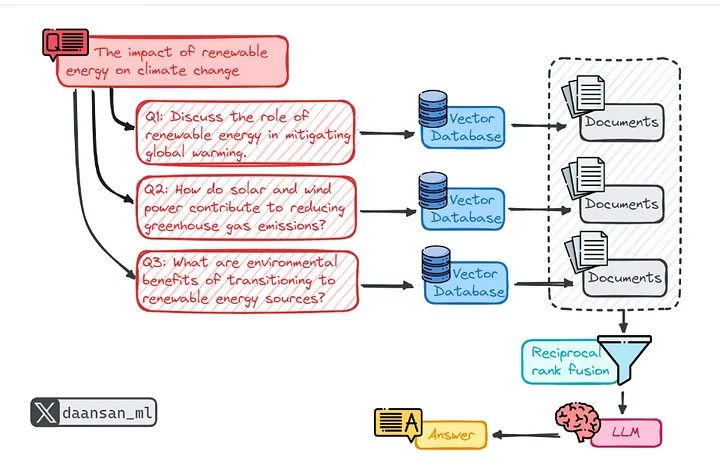

In [48]:
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_core.documents import Document
from langchain_classic.retrievers import MultiQueryRetriever

In [49]:
all_docs = [
    Document(page_content="Regular walking boosts heart health and can reduce symptoms of depression.", metadata={"source": "H1"}),
    Document(page_content="Consuming leafy greens and fruits helps detox the body and improve longevity.", metadata={"source": "H2"}),
    Document(page_content="Deep sleep is crucial for cellular repair and emotional regulation.", metadata={"source": "H3"}),
    Document(page_content="Mindfulness and controlled breathing lower cortisol and improve mental clarity.", metadata={"source": "H4"}),
    Document(page_content="Drinking sufficient water throughout the day helps maintain metabolism and energy.", metadata={"source": "H5"}),
    Document(page_content="The solar energy system in modern homes helps balance electricity demand.", metadata={"source": "I1"}),
    Document(page_content="Python balances readability with power, making it a popular system design language.", metadata={"source": "I2"}),
    Document(page_content="Photosynthesis enables plants to produce energy by converting sunlight.", metadata={"source": "I3"}),
    Document(page_content="The 2022 FIFA World Cup was held in Qatar and drew global energy and excitement.", metadata={"source": "I4"}),
    Document(page_content="Black holes bend spacetime and store immense gravitational energy.", metadata={"source": "I5"}),
]

In [50]:
embedding_model = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2",
    model_kwargs={"device": "cpu"},
    encode_kwargs={"normalize_embeddings": True}
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [51]:
vector_store = FAISS.from_documents(
    documents = all_docs,
    embedding= embedding_model
)

In [68]:
from langchain_openai import ChatOpenAI
from langchain_huggingface import HuggingFaceEndpoint, ChatHuggingFace
import os

llm = ChatOpenAI(
    model="openai/gpt-oss-120b:fastest",
    base_url="https://router.huggingface.co/v1",
    api_key=os.environ["HF_TOKEN"],
    temperature=0
)

multi_query_retriever = MultiQueryRetriever.from_llm(
    llm = llm,
    retriever = vector_store.as_retriever(search_type = "similarity", search_kwargs={'k':5})
)


In [69]:
query = "How to improve energy levels and maintain balance?"

result=multi_query_retriever.invoke(query)

APIStatusError: Error code: 402 - {'error': 'You have no remaining credits. Purchase pre-paid credits to continue using Inference Providers. Alternatively, subscribe to PRO to get monthly included credits.'}